## Branching from one bar

`env.clone` copies the environments as they stand, their accounts, their episodes and the
streams they draw from, so a copy steps on as the original would, to the bit.
`clone(env=0, n=k)` forks one environment into k copies, each to try a plan of its own from
the same bar, for planning or a counterfactual. Bitcoin's hourly perpetual at Bybit.

In [1]:
import pathlib

import exchange_router
import matplotlib.pyplot
import numpy
import pandas
import probatum

matplotlib.pyplot.style.use(style="../oceano.mplstyle")

print(f"probatum {probatum.__version__}, exchange-router {exchange_router.__version__}")

probatum 4.0.0, exchange-router 4.0.0


### The bars

In [2]:
PATH = pathlib.Path("../bars/bybit-linear-btcusdt-ethusdt-1h-2024-2025")

if PATH.exists():
    perp = probatum.Data.load(path=PATH)
else:
    with exchange_router.Router.local(exchanges=["bybit"]) as router:
        perp = probatum.Data.from_router(router, exchange="bybit", market="linear",
                                         interval="1h", symbols=["BTCUSDT", "ETHUSDT"],
                                         start="2024-01-01", end="2025-12-31", funding=True)
    perp.save(path=PATH)

train, test = perp["BTCUSDT"].split(when="2025-07-01")

### One account, part way through

One environment, held half long for 200 hours of its episode.

In [3]:
env = probatum.env(train, venue="bybit_perp", window=32, num_envs=1, seed=3)
env.reset(seed=3)

half = numpy.full(shape=(1, 1), fill_value=0.5, dtype=numpy.float32)
for _ in range(200):
    obs, reward, terminated, truncated, info = env.step(half)

row = int(info["start"][0] + info["step"][0])
print(f"episode {info['episode'][0]}, step {info['step'][0]}, at "
      f"{pandas.Timestamp(train.time[row], tz='UTC'):%Y-%m-%d %H:%M}")

episode 0, step 200, at 2024-07-15 03:00


### Five plans from here

Five copies of the account, each holding its own weight for the next two weeks; each
copy's equity is the running sum of its log returns.

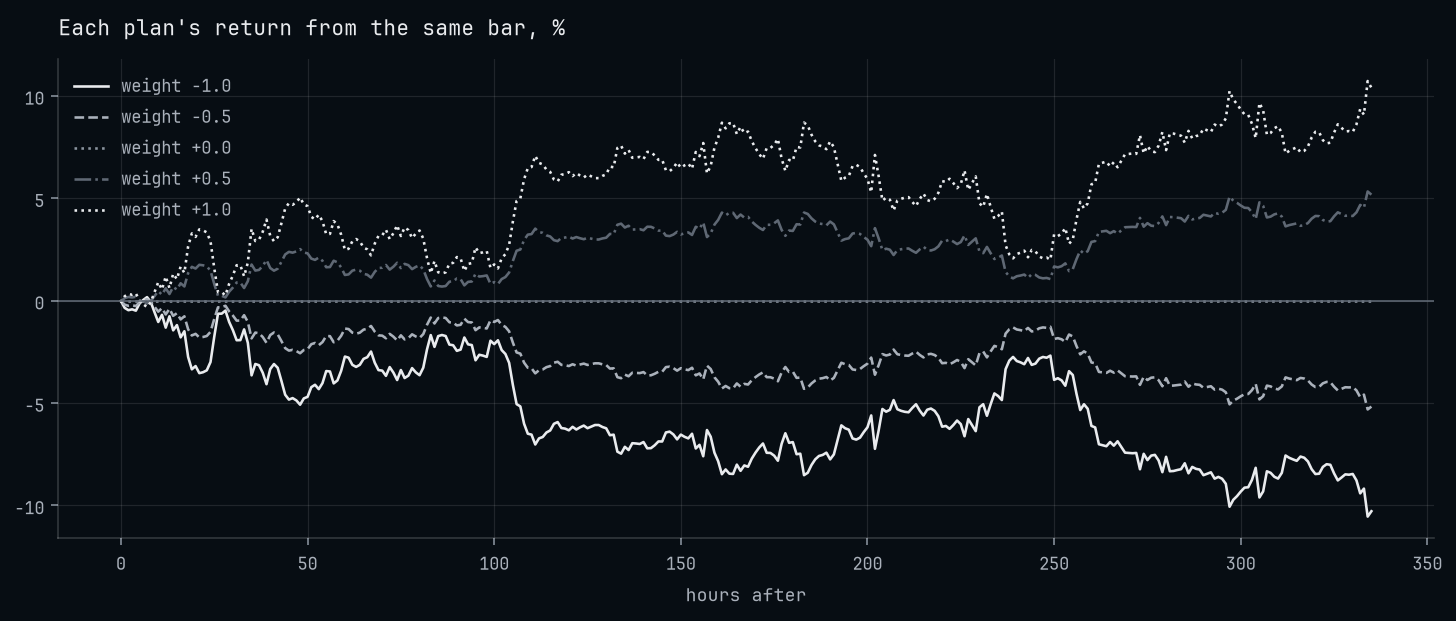

In [4]:
plans = numpy.array([[-1.0], [-0.5], [0.0], [0.5], [1.0]], dtype=numpy.float32)
fork  = env.clone(env=0, n=len(plans))

steps = []
for _ in range(24 * 14):
    _, reward, _, _, _ = fork.step(plans)
    steps.append(reward)

paths = pandas.DataFrame(numpy.exp(numpy.cumsum(steps, axis=0)) - 1.0,
                         columns=[f"weight {plan[0]:+.1f}" for plan in plans]) * 100

axes = paths.plot(title="Each plan's return from the same bar, %", xlabel="hours after")
axes.axhline(y=0.0, color="C3", linewidth=0.8)
matplotlib.pyplot.show()

### To the bit

A copy of the whole environment, stepped beside the original on the same actions, gives
the same observations and rewards, bit for bit.

In [5]:
twin = env.clone()

same = True
for _ in range(500):
    first  = env.step(half)
    second = twin.step(half)
    same   = (same and numpy.array_equal(first[0], second[0])
              and numpy.array_equal(first[1], second[1]))

print(f"500 steps, every observation and reward equal: {same}")

500 steps, every observation and reward equal: True
